# Energy Efficiency: Data Understanding, EDA and Model Comparison

**Dataset:** UCI Machine Learning Repository — *Energy Efficiency* (ENB2012), Tsanas & Xifara (2012).
Simulated residential buildings with 8 structural inputs and 2 energy outputs.

- `X1` relative compactness
- `X2` surface area (m²)
- `X3` wall area (m²)
- `X4` roof area (m²)
- `X5` overall height (m)
- `X6` orientation (2=N, 3=E, 4=S, 5=W)
- `X7` glazing area (0–0.4 of floor area)
- `X8` glazing area distribution (0–5)
- `Y1` heating load (target here), `Y2` cooling load

Source: https://archive.ics.uci.edu/dataset/242/energy+efficiency

## 1. Load the data

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt

df = pd.read_excel("../data/ENB2012_data.xlsx")
print(df.shape)
df.head()

(768, 10)


,X1,X2,X3,X4,X5,X6,X7,X8,Y1,Y2
0,0.98,514.5,294.0,110.25,7.0,2,0.0,0,15.55,21.33
1,0.98,514.5,294.0,110.25,7.0,3,0.0,0,15.55,21.33
2,0.98,514.5,294.0,110.25,7.0,4,0.0,0,15.55,21.33
3,0.98,514.5,294.0,110.25,7.0,5,0.0,0,15.55,21.33
4,0.90,563.5,318.5,122.50,7.0,2,0.0,0,20.84,28.28


## 2. Data understanding: types, missing values, duplicates, unique values

In [2]:
print("dtypes:\n", df.dtypes)
print("missing values:", int(df.isna().sum().sum()))
print("duplicate rows:", int(df.duplicated().sum()))
print("\nunique values per column:")
print(df.nunique())

dtypes:
 X1    float64
X2    float64
X3    float64
X4    float64
X5    float64
X6      int64
X7    float64
X8      int64
Y1    float64
Y2    float64
dtype: object
missing values: 0
duplicate rows: 0

unique values per column:
X1     12
X2     12
X3      7
X4      4
X5      2
X6      4
X7      4
X8      6
Y1    587
Y2    636
dtype: int64


`X6` (orientation), `X7` (glazing area) and `X8` (glazing distribution) are discrete
categorical/ordinal codes even though they are stored as numbers, while `X1`–`X5` are
continuous. There is no missing data and no exact duplicate rows, so no imputation or
de-duplication is required.

## 3. Summary statistics and class-like distributions

In [3]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
X1,768.0,0.764167,0.105777,0.62,0.6825,0.75,0.8300,0.98
X2,768.0,671.708333,88.086116,514.50,606.3750,673.75,741.1250,808.50
X3,768.0,318.500000,43.626481,245.00,294.0000,318.50,343.0000,416.50
X4,768.0,176.604167,45.165950,110.25,140.8750,183.75,220.5000,220.50
X5,768.0,5.250000,1.751140,3.50,3.5000,5.25,7.0000,7.00
X6,768.0,3.500000,1.118763,2.00,2.7500,3.50,4.2500,5.00
X7,768.0,0.234375,0.133221,0.00,0.1000,0.25,0.4000,0.40
X8,768.0,2.812500,1.550960,0.00,1.7500,3.00,4.0000,5.00
Y1,768.0,22.307195,10.090204,6.01,12.9925,18.95,31.6675,43.10
Y2,768.0,24.587760,9.513306,10.90,15.6200,22.08,33.1325,48.03


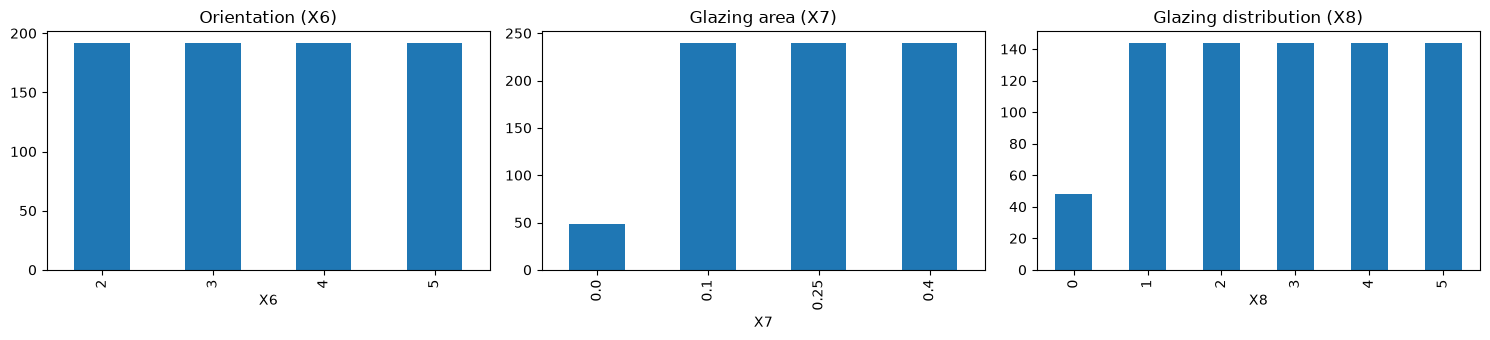

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
df["X6"].value_counts().sort_index().plot(kind="bar", ax=axes[0], title="Orientation (X6)")
df["X7"].value_counts().sort_index().plot(kind="bar", ax=axes[1], title="Glazing area (X7)")
df["X8"].value_counts().sort_index().plot(kind="bar", ax=axes[2], title="Glazing distribution (X8)")
plt.tight_layout(); plt.show()

## 4. Target distribution

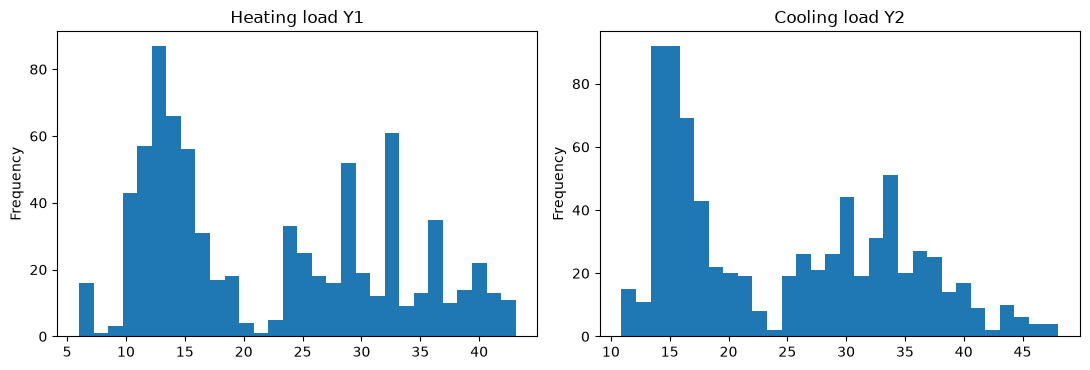

    count       mean        std    min      25%    50%      75%    max
Y1  768.0  22.307195  10.090204   6.01  12.9925  18.95  31.6675  43.10
Y2  768.0  24.587760   9.513306  10.90  15.6200  22.08  33.1325  48.03


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
df["Y1"].plot(kind="hist", bins=30, ax=axes[0], title="Heating load Y1")
df["Y2"].plot(kind="hist", bins=30, ax=axes[1], title="Cooling load Y2")
plt.tight_layout(); plt.show()
print(df[["Y1", "Y2"]].describe().T)

Heating and cooling load are strongly related (r = 0.000), which is expected. We model Y1 only, so Y2 is excluded from the features to avoid leakage.

In [6]:
print("corr(Y1, Y2) =", round(df["Y1"].corr(df["Y2"]), 3))

corr(Y1, Y2) = 0.976


## 5. Correlation with the target

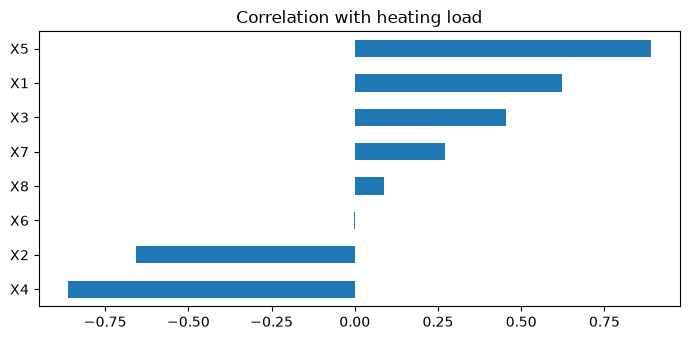

In [7]:
df.corr()["Y1"].drop(["Y1", "Y2"]).sort_values().plot(kind="barh", figsize=(7, 3.5), title="Correlation with heating load")
plt.tight_layout(); plt.show()

## 6. Feature relationships

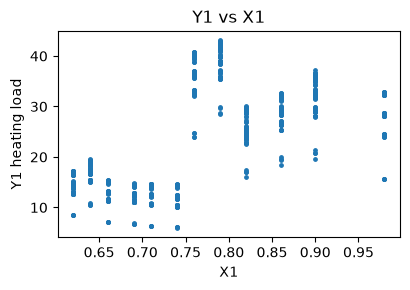

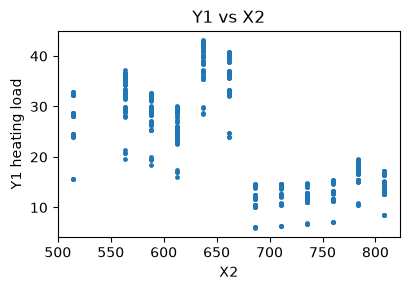

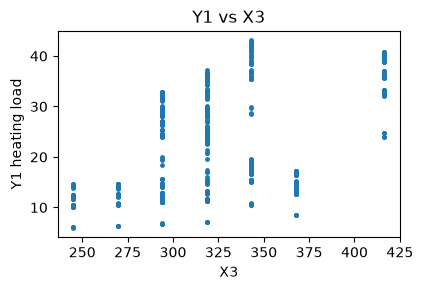

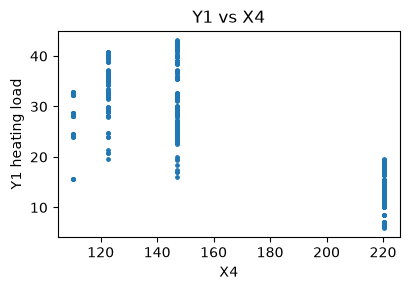

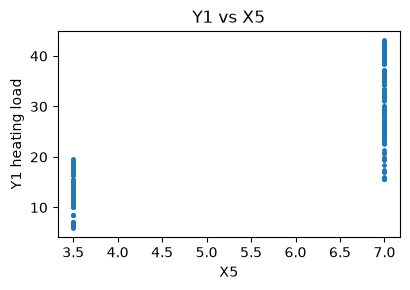

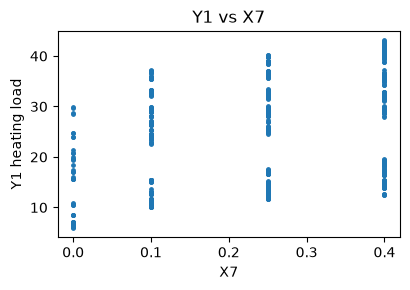

In [8]:
for col in ["X1", "X2", "X3", "X4", "X5", "X7"]:
    plt.figure(figsize=(4.2, 3))
    plt.scatter(df[col], df["Y1"], s=6)
    plt.xlabel(col); plt.ylabel("Y1 heating load"); plt.title(f"Y1 vs {col}")
    plt.tight_layout(); plt.show()

Overall height (`X5`) and relative compactness (`X1`) show the clearest patterns,
and `X4` (roof area) is strongly related to `X2`/`X3` because the geometry is
constrained. Because relationships are non-linear (especially `X1` and glazing),
tree-based and kernel models are expected to outperform plain linear regression.

## 7. Train / test split and preprocessing plan
- 80/20 split with a fixed random state.
- Standard scaling for distance- and kernel-based models (KNN, SVR), inside a `Pipeline`
  so it is fitted only on training folds.

In [9]:
from sklearn.model_selection import train_test_split
FEATURES = ["X1","X2","X3","X4","X5","X6","X7","X8"]
X, y = df[FEATURES], df["Y1"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(X_train.shape, X_test.shape)

(614, 8) (154, 8)


## 8. Model comparison with 5-fold cross-validation

In [10]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import cross_val_score, KFold

cv = KFold(n_splits=5, shuffle=True, random_state=42)
models = {
    "LinearRegression": Pipeline([("scaler", StandardScaler()), ("model", LinearRegression())]),
    "KNeighborsRegressor": Pipeline([("scaler", StandardScaler()), ("model", KNeighborsRegressor(5))]),
    "SVR": Pipeline([("scaler", StandardScaler()), ("model", SVR(C=1000, gamma=0.1))]),
    "RandomForestRegressor": Pipeline([("scaler", StandardScaler()), ("model", RandomForestRegressor(100, random_state=42))]),
}
for name, mdl in models.items():
    scores = cross_val_score(mdl, X_train, y_train, cv=cv, scoring="r2")
    print(f"{name:24s} R2 = {scores.mean():.4f} +/- {scores.std():.4f}")

LinearRegression         R2 = 0.9146 +/- 0.0109
KNeighborsRegressor      R2 = 0.9436 +/- 0.0040


SVR                      R2 = 0.9968 +/- 0.0003


RandomForestRegressor    R2 = 0.9974 +/- 0.0003


## 9. Hyperparameter tuning with GridSearchCV

In [11]:
from sklearn.model_selection import GridSearchCV

rf_tune = GridSearchCV(
    Pipeline([("scaler", StandardScaler()), ("model", RandomForestRegressor(random_state=42))]),
    {"model__n_estimators": [100, 200], "model__max_depth": [None, 10, 20], "model__min_samples_leaf": [1, 2, 4]},
    cv=cv, scoring="r2", n_jobs=-1,
)
rf_tune.fit(X_train, y_train)
print("Best params:", rf_tune.best_params_)
print("Best CV R2 :", round(rf_tune.best_score_, 4))

Best params: {'model__max_depth': None, 'model__min_samples_leaf': 1, 'model__n_estimators': 100}
Best CV R2 : 0.9974


## 10. Final evaluation on the held-out test set (run once)

R2  : 0.9977
RMSE: 0.4934
MAE : 0.354


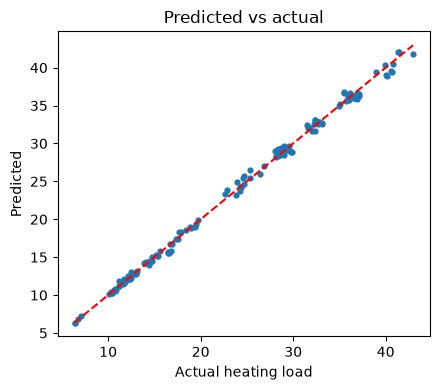

In [12]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

y_pred = rf_tune.best_estimator_.predict(X_test)
print("R2  :", round(r2_score(y_test, y_pred), 4))
print("RMSE:", round(mean_squared_error(y_test, y_pred) ** 0.5, 4))
print("MAE :", round(mean_absolute_error(y_test, y_pred), 4))

plt.figure(figsize=(4.5, 4))
plt.scatter(y_test, y_pred, s=12); plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "r--")
plt.xlabel("Actual heating load"); plt.ylabel("Predicted"); plt.title("Predicted vs actual"); plt.tight_layout(); plt.show()